<a href="https://colab.research.google.com/github/akaplin23/ECS171-Project/blob/main/logistic_regression_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Logistic Regression Model**

In [2]:
!git clone https://github.com/akaplin23/ECS171-Project.git
%cd ECS171-Project

Cloning into 'ECS171-Project'...
remote: Enumerating objects: 126, done.
remote: Counting objects: 100% (126/126), done.
remote: Compressing objects: 100% (103/103), done.
remote: Total 126 (delta 49), reused 55 (delta 18), pack-reused 0 (from 0)
Receiving objects: 100% (126/126), 2.99 MiB | 10.94 MiB/s, done.
Resolving deltas: 100% (49/49), done.
/content/ECS171-Project


**Loading files and Sanity Check**

In [3]:
import pandas as pd
import numpy as np

# Load pre-split CSV files
train_df = pd.read_csv("cleaned_data/heart_train_processed.csv")
val_df   = pd.read_csv("cleaned_data/heart_val_processed.csv")
test_df  = pd.read_csv("cleaned_data/heart_test_processed.csv")

# Separate input features X from binary target variable (y: 0 = Normal, 1 = HeartDisease)
X_train = train_df.drop(columns=["HeartDisease"])
y_train = train_df["HeartDisease"]

X_val   = val_df.drop(columns=["HeartDisease"])
y_val   = val_df["HeartDisease"]

X_test  = test_df.drop(columns=["HeartDisease"])
y_test  = test_df["HeartDisease"]

print(f"Train: {X_train.shape} | Val: {X_val.shape} | Test: {X_test.shape}")
print("Nulls remaining:", X_train.isna().sum().sum() + X_val.isna().sum().sum() + X_test.isna().sum().sum())
print("Columns:", list(X_train.columns))

Train: (587, 16) | Val: (147, 16) | Test: (184, 16)
Nulls remaining: 0
Columns: ['Age', 'Sex', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'Chol_missing', 'ChestPainType_ATA', 'ChestPainType_NAP', 'ChestPainType_TA', 'RestingECG_Normal', 'RestingECG_ST', 'ST_Slope_Flat', 'ST_Slope_Up']


**Training an Untuned Logistic Regression Baseline Model**

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, log_loss, recall_score

# Initialize and fit logistic regression model on training set
default_lr = LogisticRegression(random_state=0, max_iter=1000)
default_lr.fit(X_train, y_train)

# 0/1 Class Predictions (default 0.5 probability)
train_preds = default_lr.predict(X_train)
val_preds   = default_lr.predict(X_val)

# Probabilities for class 1 HeartDisease
val_probs = default_lr.predict_proba(X_val)[:, 1]

print(f"Default Val Accuracy : {accuracy_score(y_val, val_preds):.4f}")
print(f"Default Val Recall   : {recall_score(y_val, val_preds):.4f}")
print(f"Default Val F1-Score : {f1_score(y_val, val_preds):.4f}")
print(f"Default Val ROC-AUC  : {roc_auc_score(y_val, val_probs):.4f}")


Default Val Accuracy : 0.8639
Default Val Recall   : 0.8642
Default Val F1-Score : 0.8750
Default Val ROC-AUC  : 0.9252


**Interpreting the Metrics for the Untuned Logistic Regression Model**


---

Accuracy: 0.8639
* The model correctly classifies 86.4% of patients in validation set.

ROC-AUC: 0.9252
*   This means if you were to randomly pick a patient with heart disease and a normal patient from the validation set the model would assign a higher risk score to the heart disease patient 92.5% of the time.

Recall: 0.8642
*   The model catches 86.4% of positive class (heart disease) in validation set

F1-Score: 0.8750
* Suggests that model isn't achieving high recall by guessing majority class.




**Hyperparameter Tuning on Validation Set**

In [5]:
from sklearn.metrics import recall_score

tuning_results = []

# Loop over candidate regularization strengths (C) and penalties (l1 vs. l2)
for C in [0.001, 0.01, 0.1, 1, 10, 100]:
    for penalty in ["l1", "l2"]:
        # solver="liblinear" supports both L1 and L2 penalties on small tabular datasets
        model = LogisticRegression(
            C=C,
            penalty=penalty,
            solver="liblinear",
            random_state=0,
            max_iter=1000
        )
        # Train on X_train, evaluate strictly on X_val
        model.fit(X_train, y_train)
        val_probs = model.predict_proba(X_val)[:, 1]
        val_preds = model.predict(X_val)

        # Store all metrics for comparison
        tuning_results.append({
            "C": C,
            "penalty": penalty,
            "val_auc": roc_auc_score(y_val, val_probs),
            "val_loss": log_loss(y_val, val_probs),
            "val_acc": accuracy_score(y_val, val_preds),
            "val_recall": recall_score(y_val, val_preds),
            "val_f1": f1_score(y_val, val_preds),
            "model": model
        })

# Sort configurations by highest Validation ROC-AUC
tuning_df = pd.DataFrame(tuning_results).sort_values(by="val_auc", ascending=False)

print("Top Hyperparameter Configurations on Validation Set: ")
print(tuning_df.drop(columns=["model"]).head(5).to_string(index=False))

# Lock in the winning model for final test evaluation
best_lr = tuning_df.iloc[0]["model"]

Top Hyperparameter Configurations on Validation Set: 
   C penalty  val_auc  val_loss  val_acc  val_recall   val_f1
 0.1      l2 0.929667  0.344970 0.870748    0.876543 0.881988
 1.0      l2 0.926300  0.338330 0.870748    0.864198 0.880503
 0.1      l1 0.925178  0.363460 0.863946    0.901235 0.879518
 1.0      l1 0.924242  0.340877 0.863946    0.864198 0.875000
10.0      l2 0.923307  0.348929 0.863946    0.864198 0.875000


**Why ROC-AUC is used to pick the 'winning model'?**


---

Initially, Recall seemed like the best metric to use because it is important that patients with heart disease don't receieve a false negative. However, Recall as well as other metrics like Accuracy and F1, only evaluates at a single cutoff line (in our case 0.5). This means two models could score identically at 0.5 even if one model barely separates sick and healthy patients (assigning 0.51 vs. 0.49) while the other separates them confidently (0.95 vs. 0.10). ROC-AUC evaluates across every possible probability cutoff. Once you have a strong ranking, a doctor may lower the cutoff to catch more cases without retraining the model.

**Hyperparameter Tuning Conclusion**


---

C = 0.1 with l2 (Ridge) penalty has the highest ROC-AUC, accuracy, and F1 Score.

When we increase C greater than 0.1 (which means decreasing regularization), ROC-AUC begins to decrease. This causes a risk of overfitting as less regularization causes the model to fit to noise in the training set.

l2 (ridge) beat l1 (lasso) on predicted risk probability. All l1's val_loss were higher than l2's. A lower val_loss is better because it measures how wrong your model's predicted risk probabilities are. l2's val_loss is less so the model's probability estimates are better calibrated.

**Final Evaluation on Test Set**

In [6]:
from sklearn.metrics import classification_report, confusion_matrix
# final predictions on test set
test_preds = best_lr.predict(X_test)
test_probs = best_lr.predict_proba(X_test)[:, 1]

# Extracting true pos/neg and false pos/neg
tn, fp, fn, tp = confusion_matrix(y_test, test_preds).ravel()
specificity = tn / (tn + fp) # how often normal patients are correctly cleared
sensitivity = tp / (tp + fn) # Recall: how often heart disease patients are correctly caught/really important medical classification

print("Test Set Performance:")
print(classification_report(y_test, test_preds, digits=4))
print(f"Accuracy    : {accuracy_score(y_test, test_preds):.4f}")
print(f"Sensitivity : {sensitivity:.4f} (Recall for HeartDisease=1)")
print(f"Specificity : {specificity:.4f} (Recall for HeartDisease=0)")
print(f"F1-Score    : {f1_score(y_test, test_preds):.4f}")
print(f"ROC-AUC     : {roc_auc_score(y_test, test_probs):.4f}")
print(f"Log-Loss    : {log_loss(y_test, test_probs):.4f}")
print(f"\nConfusion Matrix:\n[[TN={tn}, FP={fp}]\n [FN={fn}, TP={tp}]]")

Test Set Performance:
              precision    recall  f1-score   support

           0     0.8276    0.8780    0.8521        82
           1     0.8969    0.8529    0.8744       102

    accuracy                         0.8641       184
   macro avg     0.8622    0.8655    0.8632       184
weighted avg     0.8660    0.8641    0.8644       184

Accuracy    : 0.8641
Sensitivity : 0.8529 (Recall for HeartDisease=1)
Specificity : 0.8780 (Recall for HeartDisease=0)
F1-Score    : 0.8744
ROC-AUC     : 0.9389
Log-Loss    : 0.3510

Confusion Matrix:
[[TN=72, FP=10]
 [FN=15, TP=87]]


### **Test Set Visualizations**

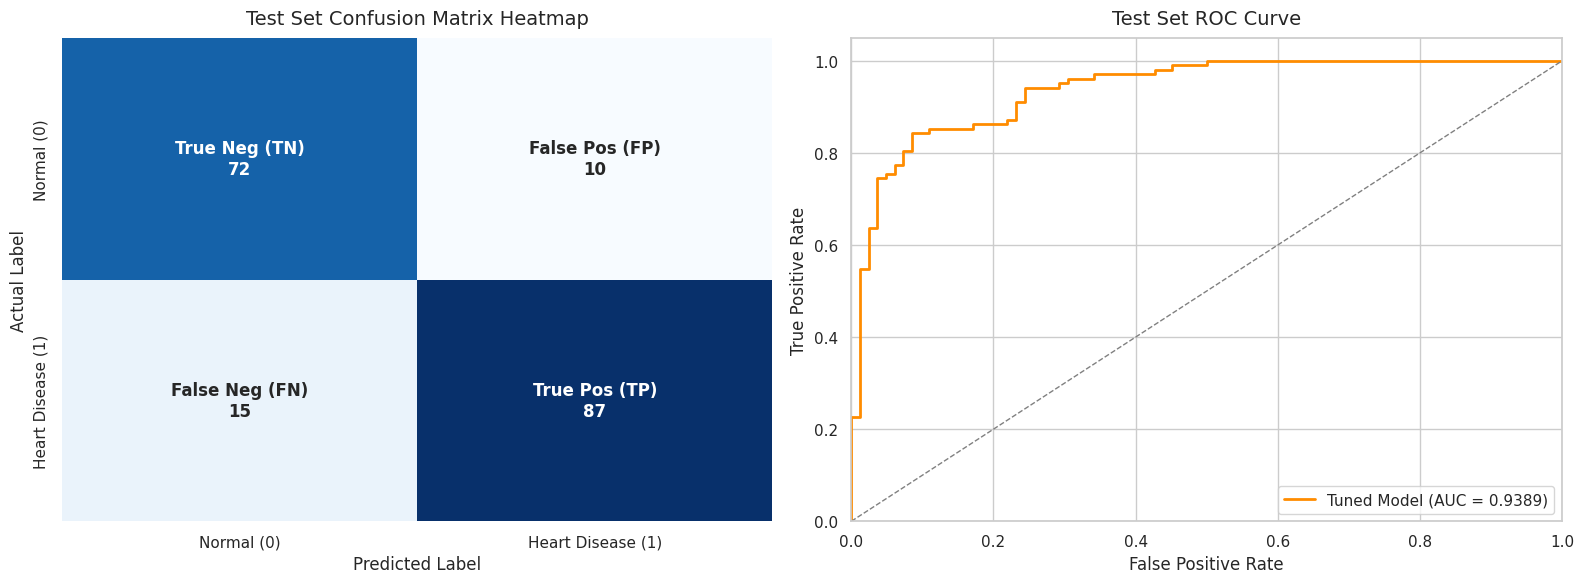

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, auc

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# test set confusion matrix
cm = confusion_matrix(y_test, test_preds)
cm_labels = np.array([["True Neg (TN)\n" + str(tn), "False Pos (FP)\n" + str(fp)],
                      ["False Neg (FN)\n" + str(fn), "True Pos (TP)\n" + str(tp)]])

sns.heatmap(cm, annot=cm_labels, fmt="", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["Normal (0)", "Heart Disease (1)"],
            yticklabels=["Normal (0)", "Heart Disease (1)"],
            annot_kws={"size": 12, "weight": "bold"})
axes[0].set_title("Test Set Confusion Matrix Heatmap", fontsize=14, pad=10)
axes[0].set_ylabel("Actual Label", fontsize=12)
axes[0].set_xlabel("Predicted Label", fontsize=12)

# test set ROC curve
fpr, tpr, _ = roc_curve(y_test, test_probs)
roc_auc = auc(fpr, tpr)

axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'Tuned Model (AUC = {roc_auc:.4f})')
axes[1].plot([0, 1], [0, 1], color='gray', lw=1, linestyle='--')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('False Positive Rate', fontsize=12)
axes[1].set_ylabel('True Positive Rate', fontsize=12)
axes[1].set_title('Test Set ROC Curve', fontsize=14, pad=10)
axes[1].legend(loc="lower right", fontsize=11)

plt.tight_layout()
plt.show()

**Metric Evaluation**


---

True Positives (correctly flagged as having heart disease): 87/102

False Positives (normal but flagged at 0.50 cutoff): 10/82

True Negatives (correctly identified as normal): 72/82

False Negatives (incorrectly identified as normal): 15/102

Sensitivity: Catches 85.3% of heart disease patients.

Specificity: Identifies 87.8% of normal patients.



---



**Takeaway**: Across all possible thresholds, the model ranks a randomly chosen heart disease patient above a randomly chosen healthy patient 93.9% of the time on held-out test data. The current threshold of 0.50 is slightly conservative when identifying heartdisease with False Negatives being 15/102. If we wanted to reduce the false negatives we could lower the probability threshold.



**Learned Feature Weights**

In [ ]:
coef_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": best_lr.coef_[0],
    "Odds_Ratio": np.exp(best_lr.coef_[0])
}).sort_values(by="Coefficient", ascending=False)

print(coef_df.to_string(index=False))

          Feature  Coefficient  Odds_Ratio
     Chol_missing     0.852637    2.345824
              Sex     0.768573    2.156686
    ST_Slope_Flat     0.692576    1.998857
   ExerciseAngina     0.675304    1.964629
        FastingBS     0.457540    1.580182
          Oldpeak     0.306903    1.359209
              Age     0.135961    1.145637
        RestingBP     0.126545    1.134900
      Cholesterol     0.079636    1.082893
RestingECG_Normal    -0.115353    0.891052
    RestingECG_ST    -0.179550    0.835647
            MaxHR    -0.311057    0.732672
 ChestPainType_TA    -0.401414    0.669373
ChestPainType_NAP    -0.663129    0.515237
ChestPainType_ATA    -0.672200    0.510584
      ST_Slope_Up    -0.928112    0.395299


**Features with Most Influence on Heart Disease**

---

A positive coefficient and Odds_Ratio > 1 increases the odds of heart disease. The features that correlate the most with heart disease are then Chol_missing, Sex, ST_Slope_Flat, and ExerciseAngina. A negative correlation or Odd_Ratio < 1 decreases the odds of heart disease. So a lower heart disease risk correlate with features: ST_Slope_Up, ChestPainType_ATA, and ChestPainType_NAP.


In [ ]:
import joblib, pathlib

pathlib.Path("models").mkdir(exist_ok=True)
joblib.dump(best_lr, "models/logistic_regression_baseline.joblib")

pd.DataFrame({
    "y_true": y_test,
    "lr_pred": test_preds,
    "lr_prob": test_probs
}).to_csv("models/lr_test_predictions.csv", index=False)